# Session 15 lab: Build your capstone

<p class="lead">
Turn four business cases into one argued decision. Record your evidence in a register that others can check, test it with a validation checklist, look at several domains side by side without inventing links, weigh the options openly, and repair a capstone draft that makes four classic mistakes.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/15_capstone_studio_lab.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

> *Chief operating officer (teaching frame): "I can fund one improvement next quarter. Bring me evidence from at least three parts of the business, tell me which option you would choose and why, show me how you checked it, and tell me what you cannot know yet."*

> **About the data: five separate contexts**
>
> Superstore is Tableau's **fictitious** sample store (amounts in the source's monetary units). The marketing, finance, operations and HR files are **synthetic** data generated **separately** by the course for fictional organisations (amounts in neutral currency units). They share no customers, orders, employees or keys. "One leadership team receiving five evidence packs" is a **teaching frame** for practising a cross-domain decision, not a fact about the data. Never join their rows or explain one with another.

---

## How this lab works

| Part | What you do | Tasks |
|---|---|---|
| **Guided practice** | Follow along step by step, everyone together | G1–G3 |
| **Independent tasks** | Your own capstone: decision, view, trade-offs | I1–I4 |
| **Challenge** | Repair a flawed draft; review a critical number | C1–C2 |

Each task has a level:

- **Core**: everyone completes it; it is enough for your portfolio.
- **Stretch**: for when you finish the core tasks early.
- **Challenge**: optional, harder reasoning.

---

## What you will be able to do

1. Recompute one finding per domain from the raw data, each under its own contract.
2. Record findings in an evidence register with metric, grain, period, value, check and limitation.
3. Write a validation checklist that tests register rows and data reconciliations automatically.
4. State one capstone decision with options, three or more evidence domains and screening notes for the rest.
5. Place monthly series from separate datasets side by side on a common calendar, with an honest caveat.
6. Build a weighted trade-off table and test whether its ranking survives changes in the weights.
7. Find and fix a false join, an invalid revenue total, causal language and missing limitations.

**Evidence you keep:** your evidence register, its validation checklist, your capstone outline, the side-by-side view, the trade-off table with its sensitivity test, and your before/after notes on the flawed draft.

---

## Before you start

- Read the [Session 15 lecture](15_capstone_studio_lecture.md).
- Have your evidence logs from the four business-case labs to hand: [finance](10_finance_budget_lab.md), [operations](11_operations_service_lab.md), [marketing](12_marketing_campaigns_lab.md) and [HR](13_hr_workforce_lab.md).

---

## Guided practice

### G1 (Core): Load the five datasets

Run the five setup cells in order, then the cell after them. You will choose three domains later, so load all five now.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


In [2]:
# Marketing data setup (synthetic). Run this cell first.
# Downloads the course's synthetic marketing data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

MARKETING_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/marketing-v1/"
MARKETING_SHA256 = {
    "marketing_daily.csv": "1cbfc8e1c91ae72d18364b2d13bdf6db513c4aec28c339ef8b91f87a60dc0a07",
    "ab_test.csv": "41a3662997111b66d7ab1eb899f4b32e26bd64c66284ce881db6b8a7300ad47f",
}
MARKETING_DIR = os.environ.get("COURSE_MARKETING_DIR", "")


def load_marketing(name):
    """Load one marketing-v1 file: 'marketing_daily.csv' or 'ab_test.csv'."""
    if MARKETING_DIR:
        with open(os.path.join(MARKETING_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(MARKETING_URL + name).read()
    if hashlib.sha256(data).hexdigest() != MARKETING_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["date"])


print("Marketing setup complete.")

Marketing setup complete.


In [3]:
# Finance data setup (synthetic). Run this cell first.
# Downloads the course's synthetic finance data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

FINANCE_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/finance-v1/"
FINANCE_SHA256 = {
    "finance_actuals.csv": "3aeb2773990f86c21a1536b8854d7290794315e8bc872420c2e5df77151ac7fd",
    "finance_budget.csv": "238dbec8e7e80a61068c12c48280ff4f9de91198879ee295366774f530efad60",
}
FINANCE_DIR = os.environ.get("COURSE_FINANCE_DIR", "")


def load_finance(name):
    """Load one finance-v1 file: 'finance_actuals.csv' or 'finance_budget.csv'."""
    if FINANCE_DIR:
        with open(os.path.join(FINANCE_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(FINANCE_URL + name).read()
    if hashlib.sha256(data).hexdigest() != FINANCE_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["month"], keep_default_na=False,
                       na_values={"amount": [""], "budget": [""]})


print("Finance setup complete.")

Finance setup complete.


In [4]:
# Operations data setup (synthetic). Run this cell first.
# Downloads the course's synthetic shipment data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

OPERATIONS_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/operations-v1/"
OPERATIONS_SHA256 = {"shipments.csv": "7b5c0860beb2a16ba4f84a3dd0b5bdf9d88e968b720c6541f1dcb7d688c75687"}
OPERATIONS_DIR = os.environ.get("COURSE_OPERATIONS_DIR", "")
CUTOFF = pd.Timestamp("2025-12-31")


def load_shipments():
    """Load operations-v1 shipments: one row per shipment, known at the end of 2025-12-31."""
    if OPERATIONS_DIR:
        with open(os.path.join(OPERATIONS_DIR, "shipments.csv"), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(OPERATIONS_URL + "shipments.csv").read()
    if hashlib.sha256(data).hexdigest() != OPERATIONS_SHA256["shipments.csv"]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["dispatch_date", "promised_date", "delivered_date"])


print("Operations setup complete.")

Operations setup complete.


In [5]:
# HR data setup (synthetic). Run this cell first.
# Downloads the course's synthetic workforce data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

HR_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/hr-v1/"
HR_SHA256 = {
    "employees.csv": "7d59a66675d53b7d6de8cce6a4d3369ddd6268e51913e86f30e9560c019342a9",
    "department_history.csv": "12e6524a7838e9d5426c2bef116769ad850d5eaf11e10958a4e4ae13d21dca36",
    "recruitment.csv": "3a6c2046fd5cbb4a07d435f50e3d10e5df160314decd1e651718a5d0bd7fbc05",
}
HR_DATES = {
    "employees.csv": ["hire_date", "exit_date"],
    "department_history.csv": ["effective_from", "effective_to"],
    "recruitment.csv": ["opened_date", "offer_accepted_date", "hire_date"],
}
HR_DIR = os.environ.get("COURSE_HR_DIR", "")
CUTOFF = pd.Timestamp("2025-12-31")


def load_hr(name):
    """Load one hr-v1 file: 'employees.csv', 'department_history.csv' or 'recruitment.csv'."""
    if HR_DIR:
        with open(os.path.join(HR_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(HR_URL + name).read()
    if hashlib.sha256(data).hexdigest() != HR_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=HR_DATES[name])


print("HR setup complete.")

HR setup complete.


In [6]:
import datetime
import re

import numpy as np

ONE_DAY = datetime.timedelta(days=1)
MONTHS = pd.date_range("2025-01-01", "2025-12-01", freq="MS")   # the common calendar: 2025 only

orders = load_orders()
marketing = load_marketing("marketing_daily.csv")
actuals = load_finance("finance_actuals.csv")
budget = load_finance("finance_budget.csv")
shipments = load_shipments()
employees = load_hr("employees.csv")
history = load_hr("department_history.csv")
print("Loaded: Superstore", len(orders), "| marketing", len(marketing), "| finance", len(actuals), "+", len(budget),
      "| shipments", len(shipments), "| employees", len(employees), "+", len(history))

Loaded: Superstore 6815 | marketing 2555 | finance 1378 + 432 | shipments 5893 | employees 520 + 543


### G2 (Core): Recompute one finding per domain

The cell below defines one small function per domain. Each one recomputes a finding from **its own** dataset, under the contract you learned in that domain's session, and returns a **register row**: claim, source, metric, grain, period, value, check and limitation. The value is always produced by code.

In [7]:
REGISTER_COLUMNS = ["claim", "source", "metric", "grain", "period", "value", "check", "limitation"]


def row(**fields):
    """One evidence-register row; every column must be given."""
    missing = set(REGISTER_COLUMNS) - set(fields)
    assert not missing, f"missing register fields: {missing}"
    return {c: fields[c] for c in REGISTER_COLUMNS}


def retail_evidence():
    r = orders[orders["order_date"].dt.year == 2025]
    by_month = r.groupby("order_month")["sales"].sum()
    q4_share = by_month.loc["2025-10-01":].sum() / by_month.sum()
    return row(claim="Store sales are concentrated in the last quarter of the year",
               source="Superstore (Tableau sample), orders placed in 2025", metric="Oct-Dec Sales / 2025 Sales",
               grain="Order line, by order month", period="Orders placed 2025-01-01 to 2025-12-31",
               value=f"{q4_share:.0%} of {by_month.sum():,.0f} source units",
               check="Monthly Sales add up to the annual total",
               limitation="Fictitious sample store; a separate context from the other datasets")


def marketing_evidence():
    c = marketing.groupby("campaign_id")[["spend", "attributed_revenue"]].sum()
    c["roas"] = c["attributed_revenue"] / c["spend"].where(c["spend"] > 0)
    below = c[c["roas"] < 1]
    return row(claim="Some campaigns return less attributed revenue than they cost",
               source="marketing-v1 marketing_daily.csv", metric="Attributed revenue / spend, ratio of sums per campaign",
               grain="Campaign-day, summed by campaign", period="2025",
               value=f"{len(below)} of {len(c)} campaigns below 1 ({', '.join(below.index)})",
               check="Ratio of sums, not mean of daily ROAS",
               limitation="Synthetic single-campaign attribution; not the incremental effect of spend")


def finance_evidence():
    keys = ["month", "department", "account"]
    a = actuals.groupby(keys, as_index=False)["amount"].sum()
    cells = a.merge(budget[keys + ["budget"]], on=keys, how="outer")
    known = cells[cells["budget"].notna()].fillna({"amount": 0.0})
    variance = known["amount"].sum() - known["budget"].sum()
    unknown = cells.loc[cells["budget"].isna(), "amount"].sum()
    return row(claim="Spending ran slightly over the comparable budget",
               source="finance-v1 actuals + budget", metric="(Actual - budget) / budget, known-budget cells",
               grain="Month x department x account cell", period="2025",
               value=f"{variance / known['budget'].sum():+.1%}; {unknown:,.0f} currency units with unknown budget",
               check="Postings aggregated before the join; budget total unchanged",
               limitation="Expense view only: no revenue or benefit side")


def operations_evidence():
    s = shipments[shipments["status"] != "canceled"]
    due = s[s["promised_date"].notna() & (s["promised_date"] <= CUTOFF)]
    on_time = due["delivered_date"].notna() & (due["delivered_date"] <= due["promised_date"])
    december = due["promised_date"].dt.month == 12
    return row(claim="On-time delivery fell sharply for December promises",
               source="operations-v1 shipments.csv", metric="On-time due shipments / all due shipments",
               grain="Shipment, by promised month", period="Promised in 2025; cutoff 2025-12-31",
               value=f"December {on_time[december].mean():.1%} of {december.sum()}; year {on_time.mean():.1%} of {len(due)}",
               check="Pending due shipments kept in the denominator",
               limitation="Descriptive; does not show why December was worse")


def hr_evidence(department="Operations"):
    h = history.sort_values(["employee_id", "effective_from"]).copy()
    h["last_interval"] = ~h.duplicated("employee_id", keep="last")
    d = h[h["department"] == department]

    def active(day):
        return int(((d["effective_from"] <= day) & (d["effective_to"].isna() | (d["effective_to"] > day))).sum())

    avg = np.mean([(active(m - ONE_DAY) + active(m + pd.offsets.MonthEnd(0))) / 2 for m in MONTHS])
    exits = int((d["last_interval"] & d["effective_to"].between("2025-01-01", CUTOFF)).sum())
    return row(claim=f"The {department} team had high turnover in 2025",
               source="hr-v1 department_history.csv", metric="Exits / mean of monthly average headcount",
               grain="Department interval, monthly", period="2025; cutoff 2025-12-31",
               value=f"{exits / avg:.0%} ({exits} exits, average headcount {avg:.0f})",
               check="Exit date treated as the first inactive day",
               limitation="Descriptive; cannot show causes, quality of work or fairness")


EVIDENCE = {"retail": retail_evidence, "marketing": marketing_evidence, "finance": finance_evidence,
            "operations": operations_evidence, "hr": hr_evidence}
print("Evidence functions ready for:", ", ".join(EVIDENCE))

Evidence functions ready for: retail, marketing, finance, operations, hr


> **Your turn:** change the code in the next cell and run it again.

In [8]:
# 1. Run the cell. Read each row: could a manager repeat the claim? Could a reviewer redo the check?
# 2. Change my_domains to the three domains you plan to use in your capstone.
# 3. Make one claim or limitation more specific by editing its function above, then run both cells again.
my_domains = ["operations", "hr", "marketing"]

assert len(my_domains) >= 3, "a capstone needs evidence from at least three domains"
register = pd.DataFrame([EVIDENCE[d]() for d in my_domains], index=pd.Index(my_domains, name="domain"))
register

,claim,source,metric,grain,period,value,check,limitation
domain,,,,,,,,
operations,On-time delivery fell sharply for December pro...,operations-v1 shipments.csv,On-time due shipments / all due shipments,"Shipment, by promised month",Promised in 2025; cutoff 2025-12-31,December 55.3% of 790; year 81.9% of 5742,Pending due shipments kept in the denominator,Descriptive; does not show why December was worse
hr,The Operations team had high turnover in 2025,hr-v1 department_history.csv,Exits / mean of monthly average headcount,"Department interval, monthly",2025; cutoff 2025-12-31,"54% (89 exits, average headcount 165)",Exit date treated as the first inactive day,"Descriptive; cannot show causes, quality of wo..."
marketing,Some campaigns return less attributed revenue ...,marketing-v1 marketing_daily.csv,"Attributed revenue / spend, ratio of sums per ...","Campaign-day, summed by campaign",2025,"2 of 7 campaigns below 1 (DISP-01, VID-01)","Ratio of sums, not mean of daily ROAS",Synthetic single-campaign attribution; not the...


> **One finding per domain is the minimum**
>
> A strong capstone usually has two or three register rows for its main domain: the headline number, a breakdown that locates the problem, and a sensitivity check. Add rows with `row(...)` in the same way.

### G3 (Core): A validation checklist

A register is only useful if its rows are **checkable**. The function below tests every row for six things a reviewer would look for. Then a second set of checks tests the **data**: totals that must reconcile for each domain.

In [9]:
CAUSAL_WORDS = ["caused", "causes", "because of", "led to", "drove", "drives", "driven by", "due to", "resulted in"]
VAGUE_CHECKS = ["looks", "seems", "eyeball", "obvious"]


def causal_words_in(text):
    """Causal words or phrases found in `text` (whole words only)."""
    return [w for w in CAUSAL_WORDS if re.search(rf"\b{w}\b", text.lower())]


def validate_register(register):
    """Test each register row; returns a PASS/FAIL table, one row per claim."""
    results = {}
    for idx, r in register.iterrows():
        text = {c: str(r[c]).strip() for c in REGISTER_COLUMNS}
        results[idx] = {
            "all fields filled": all(text.values()),
            "value contains a number": any(ch.isdigit() for ch in text["value"]),
            "period names a year or cutoff": any(k in text["period"] for k in ["2025", "cutoff"]),
            "check is a real check": text["check"] != "" and not any(w in text["check"].lower() for w in VAGUE_CHECKS),
            "limitation is specific": len(text["limitation"]) >= 20,
            "claim avoids causal words": not causal_words_in(text["claim"]),
        }
    return pd.DataFrame(results).T.replace({True: "PASS", False: "FAIL"})


validate_register(register)

,all fields filled,value contains a number,period names a year or cutoff,check is a real check,limitation is specific,claim avoids causal words
operations,PASS,PASS,PASS,PASS,PASS,PASS
hr,PASS,PASS,PASS,PASS,PASS,PASS
marketing,PASS,PASS,PASS,PASS,PASS,PASS


In [10]:
def data_checks(domain):
    """Reconciliations that must hold for each domain's raw data."""
    if domain == "retail":
        r = orders[orders["order_date"].dt.year == 2025]
        return {"monthly Sales add up to the 2025 total": np.isclose(r.groupby("order_month")["sales"].sum().sum(),
                                                                     r["sales"].sum())}
    if domain == "marketing":
        return {"one row per day and campaign": not marketing.duplicated(["date", "campaign_id"]).any(),
                "funnel bounds hold": bool((marketing["clicks"] <= marketing["impressions"]).all()
                                           and (marketing["conversions"] <= marketing["sessions"]).all())}
    if domain == "finance":
        keys = ["month", "department", "account"]
        cells = actuals.groupby(keys, as_index=False)["amount"].sum().merge(budget, on=keys, how="outer")
        return {"posting total kept after aggregation": np.isclose(cells["amount"].sum(), actuals["amount"].sum()),
                "budget not multiplied by the join": np.isclose(cells["budget"].sum(), budget["budget"].sum())}
    if domain == "operations":
        canceled = shipments["status"] == "canceled"
        unknown = ~canceled & shipments["promised_date"].isna()
        not_due = ~canceled & (shipments["promised_date"] > CUTOFF)
        due = ~canceled & (shipments["promised_date"] <= CUTOFF)
        return {"populations add back to all shipments": (canceled.sum() + unknown.sum() + not_due.sum()
                                                          + due.sum()) == len(shipments)}
    if domain == "hr":
        h = history.sort_values(["employee_id", "effective_from"])
        last = ~h.duplicated("employee_id", keep="last")
        return {"department exits add up to company exits":
                (last & h["effective_to"].between("2025-01-01", CUTOFF)).sum()
                == employees["exit_date"].between("2025-01-01", CUTOFF).sum()}
    raise ValueError(f"unknown domain: {domain}")


def validation_checklist(register):
    """Register checks plus data reconciliations for every domain in the register."""
    rows = [{"item": f"{idx}: {name}", "result": result}
            for idx, r in validate_register(register).iterrows() for name, result in r.items()]
    for domain in register.index.unique():
        if domain not in EVIDENCE:
            rows.append({"item": f"{domain} data: no reconciliation defined", "result": "FAIL"})
            continue
        rows += [{"item": f"{domain} data: {name}", "result": "PASS" if ok else "FAIL"}
                 for name, ok in data_checks(domain).items()]
    table = pd.DataFrame(rows).set_index("item")
    print(f"{(table['result'] == 'PASS').sum()} of {len(table)} checks pass")
    return table

> **Your turn:** change the code in the next cell and run it again.

In [11]:
# 1. Run the cell. Every check should PASS for the default register.
# 2. Add a weak row (uncomment the two lines below) and run again. Which checks fail, and why?
# 3. Add one check of your own to validate_register, for example "source names a dataset version (-v1)".
checklist_register = register.copy()
# checklist_register.loc["weak"] = row(claim="Staffing drove the delays", source="HR", metric="turnover", grain="",
#                                      period="recent", value="high", check="chart looks bad", limitation="")
validation_checklist(checklist_register)

22 of 22 checks pass


,result
item,
operations: all fields filled,PASS
operations: value contains a number,PASS
operations: period names a year or cutoff,PASS
operations: check is a real check,PASS
operations: limitation is specific,PASS
operations: claim avoids causal words,PASS
hr: all fields filled,PASS
hr: value contains a number,PASS
hr: period names a year or cutoff,PASS


Write one line in your evidence log: how many checks your register passes, and what you changed to make it pass.

---

## Independent tasks

### I1 (Core): Choose your decision and draft the capstone outline

Fill in the outline for **your** capstone. The default is the decision from the lecture; replace every value with your own. The check below the outline enforces the capstone rules: at least three evidence domains, all five domains accounted for, at least two options and some limitations.

> **Your turn:** change the code in the next cell and run it again.

In [12]:
# 1. Run the cell to see the default outline and its checks.
# 2. Replace the stakeholder, decision, options and domains with your own capstone.
# 3. Write a one-sentence screening note for each domain you are NOT using as evidence.
outline = {
    "stakeholder": "Chief operating officer",
    "decision": "Which one improvement to fund next quarter",
    "options": ["A: carrier and peak capacity review", "B: Operations retention programme",
                "C: shift marketing budget", "D: renegotiate software contracts"],
    "evidence_domains": ["operations", "hr", "marketing"],
    "screening_notes": {
        "retail": "Context only: shows a year-end demand peak in a separate fictitious store; supports no option directly.",
        "finance": "Checked: overall variance is small; software overspend is real but small next to the other options.",
    },
    "key_metrics": ["On-time rate (due population)", "Annual turnover on average headcount", "ROAS (ratio of sums)"],
    "validation_plan": "Register checklist, domain reconciliations, one hand check and one corrected bug per domain",
    "expected_action": "Fund option A for the next peak; monitor the monthly on-time rate by carrier",
    "limitations": ["Separate fictional contexts: no cross-domain causes",
                    "All findings descriptive", "Scores in the trade-off table are judgements"],
}

ALL_DOMAINS = {"retail", "finance", "operations", "marketing", "hr"}
covered = set(outline["evidence_domains"]) | set(outline["screening_notes"])
outline_checks = {
    "at least three evidence domains": len(set(outline["evidence_domains"])) >= 3,
    "all five domains used or screened": covered == ALL_DOMAINS,
    "no domain both used and screened": not set(outline["evidence_domains"]) & set(outline["screening_notes"]),
    "at least two options": len(outline["options"]) >= 2,
    "at least two limitations": len(outline["limitations"]) >= 2,
}
for key, value in outline.items():
    print(f"{key:>16}: {value}")
print()
for name, ok in outline_checks.items():
    print("PASS" if ok else "FAIL", "-", name)

     stakeholder: Chief operating officer
        decision: Which one improvement to fund next quarter
         options: ['A: carrier and peak capacity review', 'B: Operations retention programme', 'C: shift marketing budget', 'D: renegotiate software contracts']
evidence_domains: ['operations', 'hr', 'marketing']
 screening_notes: {'retail': 'Context only: shows a year-end demand peak in a separate fictitious store; supports no option directly.', 'finance': 'Checked: overall variance is small; software overspend is real but small next to the other options.'}
     key_metrics: ['On-time rate (due population)', 'Annual turnover on average headcount', 'ROAS (ratio of sums)']
 validation_plan: Register checklist, domain reconciliations, one hand check and one corrected bug per domain
 expected_action: Fund option A for the next peak; monitor the monthly on-time rate by carrier
     limitations: ['Separate fictional contexts: no cross-domain causes', 'All findings descriptive', 'Scores in 

> **A good capstone decision is narrow**
>
> "Improve the business" is not a decision. "Which one of four funded improvements to choose for next quarter" is. If your decision needs data none of the datasets contains, narrow it until it does.

### I2 (Core): The side-by-side monthly view, with its caveat

Each series below is built **inside its own dataset** and then placed on the common 2025 calendar. Pick four series for your capstone's context view. The cell checks that each month appears exactly once (so nothing is multiplied), draws one panel per series with its own units, and prints the caveat.

In [13]:
def monthly(series):
    """Put a series indexed by a monthly timestamp onto the 2025 calendar."""
    return series.reindex(MONTHS)


retail_2025 = orders[orders["order_date"].dt.year == 2025]
mk_month = marketing["date"].dt.to_period("M").dt.to_timestamp()
s_due = shipments[(shipments["status"] != "canceled") & (shipments["promised_date"] <= CUTOFF)].copy()
s_due["on_time"] = s_due["delivered_date"].notna() & (s_due["delivered_date"] <= s_due["promised_date"])
s_month = s_due["promised_date"].dt.to_period("M").dt.to_timestamp()
fin_known = actuals.groupby(["month", "department", "account"], as_index=False)["amount"].sum().merge(
    budget, on=["month", "department", "account"], how="inner")
ops_hist = history[history["department"] == "Operations"]
ops_closing = pd.Series({m: int(((ops_hist["effective_from"] <= m + pd.offsets.MonthEnd(0))
                                 & (ops_hist["effective_to"].isna()
                                    | (ops_hist["effective_to"] > m + pd.offsets.MonthEnd(0)))).sum())
                         for m in MONTHS})

SERIES = {   # name: (monthly values, y-axis label)
    "Retail Sales": (monthly(retail_2025.groupby("order_month")["sales"].sum()), "Source monetary units"),
    "Retail orders": (monthly(retail_2025.groupby("order_month")["order_id"].nunique()), "Distinct orders"),
    "Marketing spend": (monthly(marketing.groupby(mk_month)["spend"].sum()), "Currency units"),
    "Marketing conversions": (monthly(marketing.groupby(mk_month)["conversions"].sum()), "Conversions"),
    "Finance variance": (monthly(fin_known.groupby("month")["amount"].sum() - fin_known.groupby("month")["budget"].sum()),
                         "Currency units (actual - budget)"),
    "Operations on-time rate": (monthly(s_due.groupby(s_month)["on_time"].mean() * 100), "% of due shipments"),
    "Operations due shipments": (monthly(s_due.groupby(s_month).size()), "Due shipments"),
    "HR Operations headcount": (ops_closing, "Employees at month end"),
}
print("Series available:", ", ".join(SERIES))

Series available: Retail Sales, Retail orders, Marketing spend, Marketing conversions, Finance variance, Operations on-time rate, Operations due shipments, HR Operations headcount


> **Your turn:** change the code in the next cell and run it again.

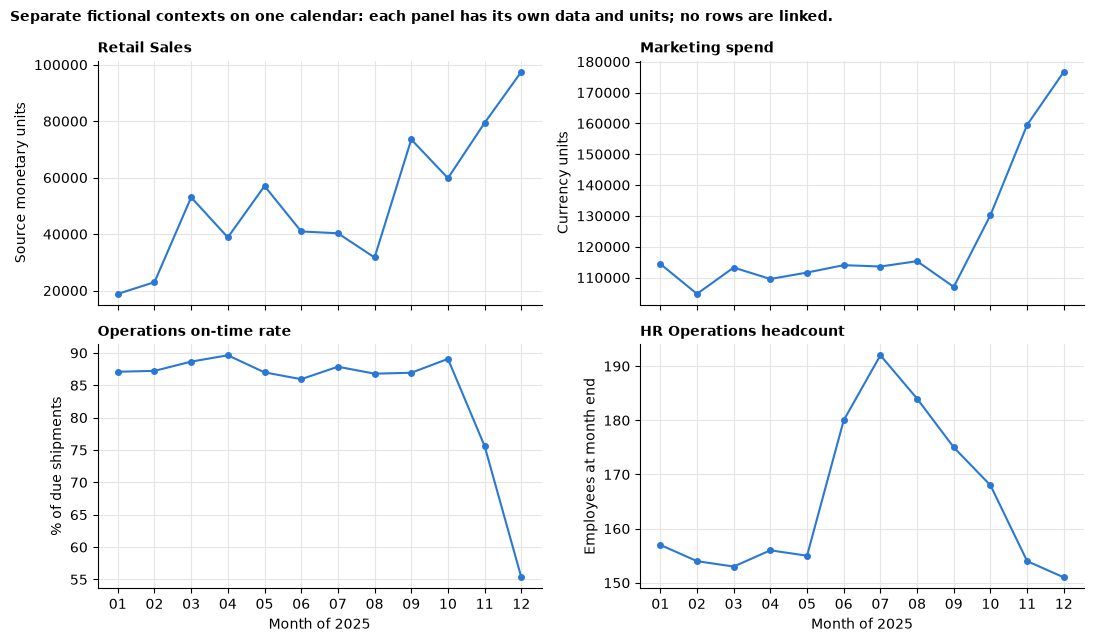

Correlations across 12 months (description only, NOT evidence of a link):


,Retail Sales,Marketing spend,Operations on-time rate,HR Operations headcount
Retail Sales,1.00,0.76,-0.72,-0.25
Marketing spend,0.76,1.00,-0.91,-0.34
Operations on-time rate,-0.72,-0.91,1.00,0.35
HR Operations headcount,-0.25,-0.34,0.35,1.00


In [14]:
# 1. Run the cell. Describe the shape of each panel in one sentence, in its own units.
# 2. Change panels to the four series that give context to YOUR decision.
# 3. Rewrite the caveat so it names your datasets. Which pair correlates most strongly? Why is that not evidence?
panels = ["Retail Sales", "Marketing spend", "Operations on-time rate", "HR Operations headcount"]
caveat = "Separate fictional contexts on one calendar: each panel has its own data and units; no rows are linked."

view = pd.concat({name: SERIES[name][0] for name in panels}, axis=1)
view.index = view.index.strftime("%Y-%m")
assert len(view) == 12 and view.index.is_unique, "expected exactly one row per month"
assert view.notna().all().all(), "a month is missing in one of the series"

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for ax, name in zip(axes.flat, panels):
    ax.plot(range(12), view[name], marker="o", markersize=4, color="#2a78d6")
    ax.set_title(name, fontsize=10)
    ax.set_ylabel(SERIES[name][1])
for ax in axes[1]:
    ax.set_xticks(range(12), [m[5:] for m in view.index])
    ax.set_xlabel("Month of 2025")
fig.suptitle(caveat, fontweight="bold", x=0.01, ha="left", fontsize=10)
fig.tight_layout()
plt.show()

print("Correlations across 12 months (description only, NOT evidence of a link):")
view.corr().round(2)

> **Hint**
>
> Two series that both build towards the end of the year will correlate strongly whatever their source. With 12 points and a shared seasonal shape, a correlation tells you about the **calendar**, not about a connection.

### I3 (Core): Trade-off table with weight sensitivity

Score **your** options. Keep a reason for every row, make the weights add to 1, then run the two sensitivity tests from the lecture.

> **Your turn:** change the code in the next cell and run it again.

In [15]:
# 1. Run the cell. Which option wins, and does it stay first in the one-at-a-time test?
# 2. Replace the options, scores and reasons with your own (scores 1-5; 5 is always "better", so cost 5 = cheap).
# 3. Change the weights to reflect what YOUR stakeholder cares about. Does the winner change?
scores = pd.DataFrame({
    "size":     [5, 4, 3, 2],
    "evidence": [4, 3, 2, 5],
    "cost":     [3, 3, 5, 4],
    "speed":    [4, 2, 5, 3],
    "urgency":  [5, 4, 2, 2],
}, index=["A: carrier and peak capacity", "B: Operations retention", "C: marketing budget shift", "D: software contracts"])
reasons = ["Large December drop on many shipments", "High turnover; causes unknown, slow to act",
           "Cheap and fast, but attribution is not incremental", "Well-measured but small overspend"]
weights = pd.Series({"size": 0.30, "evidence": 0.25, "cost": 0.15, "speed": 0.15, "urgency": 0.15})

assert abs(weights.sum() - 1) < 1e-9, "weights must add up to 1"
assert scores.isin([1, 2, 3, 4, 5]).all().all(), "scores must be whole numbers from 1 to 5"
table = scores.assign(weighted=scores @ weights, reason=reasons).sort_values("weighted", ascending=False)
display(table)

tests = []
for criterion in weights.index:
    for factor in (0.5, 2.0):
        w = weights.copy()
        w[criterion] *= factor
        w = w / w.sum()
        tests.append({"criterion": criterion, "weight x": factor, "winner": (scores @ w).idxmax()})
tests = pd.DataFrame(tests)
print(f"One-at-a-time: the top option stays first in {(tests['winner'] == table.index[0]).sum()} of {len(tests)} tests")

rng = np.random.default_rng(seed=15)
random_weights = rng.dirichlet(np.ones(len(weights)), size=2000)
winners = pd.Series(scores.index[(scores.to_numpy() @ random_weights.T).argmax(axis=0)])
winners.value_counts(normalize=True).reindex(scores.index, fill_value=0).map("{:.0%}".format).to_frame("ranked first")

,size,evidence,cost,speed,urgency,weighted,reason
A: carrier and peak capacity,5,4,3,4,5,4.30,Large December drop on many shipments
B: Operations retention,4,3,3,2,4,3.30,"High turnover; causes unknown, slow to act"
D: software contracts,2,5,4,3,2,3.20,Well-measured but small overspend
C: marketing budget shift,3,2,5,5,2,3.20,"Cheap and fast, but attribution is not increme..."


One-at-a-time: the top option stays first in 10 of 10 tests


,ranked first
A: carrier and peak capacity,78%
B: Operations retention,0%
C: marketing budget shift,16%
D: software contracts,6%


Write two sentences in your evidence log: the recommended option with its weighted score, and how robust the ranking is to the weights.

### I4 (Stretch): What would change the ranking?

Executives often ask "what would make you choose differently?". For each other option and criterion, the cell below works out how many **points** that option's score would need to rise for it to catch up with the winner ("needs"), next to how far that score can still rise on the 1-to-5 scale ("room"). When "needs" is larger than "room", that criterion **cannot** change the decision on its own; if no cell is possible, no single disputed score can flip the recommendation.

> **Your turn:** change the code in the next cell and run it again.

In [16]:
# 1. Run the cell. Which option comes closest to catching up, and on which criterion?
# 2. Is that score one you are unsure about? If so, what evidence would settle it?
# 3. Run it with your own scores and weights from I3.
totals = scores @ weights
winner = totals.idxmax()
needed = pd.DataFrame({c: (totals[winner] - totals) / weights[c] for c in weights.index}).drop(index=winner)
room = 5 - scores.drop(index=winner)          # how far each score can still rise on the 1-5 scale
possible = needed <= room
print(f"Winner: {winner}. Single score changes that could flip the decision: {int(possible.sum().sum())}")
needed.round(1).astype(str).radd("needs +") + " / room +" + room.astype(str)

Winner: A: carrier and peak capacity. Single score changes that could flip the decision: 0


,size,evidence,cost,speed,urgency
B: Operations retention,needs +3.3 / room +1,needs +4.0 / room +2,needs +6.7 / room +2,needs +6.7 / room +3,needs +6.7 / room +1
C: marketing budget shift,needs +3.7 / room +2,needs +4.4 / room +3,needs +7.3 / room +0,needs +7.3 / room +0,needs +7.3 / room +3
D: software contracts,needs +3.7 / room +3,needs +4.4 / room +0,needs +7.3 / room +1,needs +7.3 / room +2,needs +7.3 / room +3


---

## Challenge

### C1 (Challenge): Repair a flawed capstone draft

A colleague's capstone draft has four problems from the lecture. Each cell below contains **one** of them and a check. For each one:

1. Run the cell as it is and write down the result (**before**).
2. Fix the line(s) marked `# FIX ME`, run again and write down the result (**after**).
3. Write one sentence saying what the mistake would have made the leadership team believe.

**Problem 1: the grand join.**

> **Your turn:** change the code in the next cell and run it again.

In [17]:
retail_2025 = orders[orders["order_date"].dt.year == 2025]
mk = marketing.assign(order_month=marketing["date"].dt.to_period("M").dt.to_timestamp())

combined = retail_2025.merge(mk, on="order_month")                                  # FIX ME
draft_monthly = combined.groupby("order_month").agg(sales=("sales", "sum"), spend=("spend", "sum"))

ok = (np.isclose(draft_monthly["sales"].sum(), retail_2025["sales"].sum())
      and np.isclose(draft_monthly["spend"].sum(), marketing["spend"].sum()))
print(f"Rows: {len(retail_2025):,} order lines -> {len(combined):,} after the join")
print("CHECK:", "PASS" if ok else "FAIL - totals changed: rows were multiplied")

Rows: 2,634 order lines -> 562,051 after the join
CHECK: FAIL - totals changed: rows were multiplied


> **Hint**
>
> Aggregate each dataset to one row per month **first**, then line them up with `pd.concat([...], axis=1)`. You do not need a row-level join at all.

**Problem 2: adding marketing revenue to retail Sales.**

> **Your turn:** change the code in the next cell and run it again.

In [18]:
retail_sales = orders.loc[orders["order_date"].dt.year == 2025, "sales"].sum()
attributed = marketing["attributed_revenue"].sum()

headline_figures = {
    "Total 2025 revenue": retail_sales + attributed,                                 # FIX ME
}

summed = any(np.isclose(v, retail_sales + attributed) for v in headline_figures.values())
labelled = all("units" in k for k in headline_figures)
for k, v in headline_figures.items():
    print(f"{k}: {v:,.0f}")
print("CHECK:", "PASS" if not summed and labelled and len(headline_figures) == 2
      else "FAIL - report each figure separately, each labelled with its units and context")

Total 2025 revenue: 6,663,035
CHECK: FAIL - report each figure separately, each labelled with its units and context


> **Hint**
>
> Two entries, each named with its context and units, for example "Superstore Sales (source monetary units)". Then ask: even inside one real company, why would adding attributed revenue to total sales count some sales twice?

**Problem 3: causal language.**

> **Your turn:** change the code in the next cell and run it again.

In [19]:
draft_text = ("Higher marketing spend caused the December delivery collapse, and staff exits drove "
              "the fall in on-time performance.")                                   # FIX ME

found = causal_words_in(draft_text)
print(draft_text)
print("CHECK:", "PASS" if not found else f"FAIL - causal words found: {found}")

Higher marketing spend caused the December delivery collapse, and staff exits drove the fall in on-time performance.
CHECK: FAIL - causal words found: ['caused', 'drove']


> **Hint**
>
> Removing the words is not enough: the sentence must also stop linking separate contexts. Describe each domain's finding on its own, with its period and its number, and say what the data cannot show.

**Problem 4: missing limitations and vague checks.**

> **Your turn:** change the code in the next cell and run it again.

In [20]:
draft_register = pd.DataFrame([
    row(claim="On-time delivery fell sharply for December promises", source="operations-v1 shipments.csv",
        metric="On-time due / all due shipments", grain="Shipment, by promised month",
        period="December 2025, cutoff 2025-12-31", value=operations_evidence()["value"],
        check="looks right on the chart",                                             # FIX ME
        limitation=""),                                                                # FIX ME
    row(claim="The Operations team had high turnover in 2025", source="hr-v1 department_history.csv",
        metric="Exits / mean monthly average headcount", grain="Department interval, monthly",
        period="2025; cutoff 2025-12-31", value=hr_evidence()["value"],
        check="Exit date treated as the first inactive day",
        limitation="n/a"),                                                             # FIX ME
], index=["operations", "hr"])

result = validate_register(draft_register)
display(result)
print("CHECK:", "PASS" if (result == "PASS").all().all() else "FAIL - see the FAIL cells above")

,all fields filled,value contains a number,period names a year or cutoff,check is a real check,limitation is specific,claim avoids causal words
operations,FAIL,PASS,PASS,FAIL,FAIL,PASS
hr,PASS,PASS,PASS,PASS,FAIL,PASS


CHECK: FAIL - see the FAIL cells above


### C2 (Challenge): Review one critical number independently

In a peer review, the reviewer recomputes the number the recommendation depends on most, **without** reusing the author's code. Below, the December on-time rate is recomputed by a different route: counting with plain boolean masks on the raw table. If the two routes disagree, the claim is **not yet verified**.

> **Your turn:** change the code in the next cell and run it again.

In [21]:
# 1. Run the cell. Do the two routes agree?
# 2. Change the month to 11. Is November also unusual? Should the register say so?
# 3. Choose the critical number of YOUR capstone and recompute it here by a second route.
month = 12

not_canceled = shipments["status"] != "canceled"
promised_in_month = (shipments["promised_date"].dt.month == month) & (shipments["promised_date"] <= CUTOFF)
due_count = int((not_canceled & promised_in_month).sum())
on_time_count = int((not_canceled & promised_in_month & (shipments["delivered_date"] <= shipments["promised_date"])).sum())
second_route = on_time_count / due_count

s = shipments[not_canceled & shipments["promised_date"].notna() & (shipments["promised_date"] <= CUTOFF)]
first_route = (s.loc[s["promised_date"].dt.month == month, "delivered_date"]
               <= s.loc[s["promised_date"].dt.month == month, "promised_date"]).mean()
print(f"Route 1 (register logic): {first_route:.2%} | route 2 (raw masks): {on_time_count} / {due_count} = {second_route:.2%}")
print("CHECK:", "PASS - verified" if np.isclose(first_route, second_route) else "FAIL - investigate before using")

Route 1 (register logic): 55.32% | route 2 (raw masks): 437 / 790 = 55.32%
CHECK: PASS - verified


Then write the review of the colleague's draft from C1 in your evidence log, using the lecture's format:

1. **One strength** of the draft.
2. **One critical issue**: the problem that would most mislead the leadership team, and why.
3. **One next action**: the specific change you would ask for first.

---

## Validation checklist

- [ ] Each finding is computed inside its own dataset, under its own contract.
- [ ] Every register row has a claim, source, metric, grain, period, value from code, a real check and a specific limitation.
- [ ] `validation_checklist` passes for every domain you use.
- [ ] The outline uses at least three domains and screens the other two.
- [ ] The side-by-side view has one row per month, separate panels and units, and a caveat that the contexts are separate.
- [ ] No sentence uses causal words for co-movement or links findings across datasets.
- [ ] The trade-off table shows reasons for its scores, weights that add to 1, and a sensitivity test.
- [ ] The critical number has been recomputed by a second route.

---

## Exit ticket

1. Why do you aggregate each dataset to the month **before** placing them side by side, rather than joining their rows on month?
2. Marketing attributed revenue and Superstore Sales are both "revenue". Give two reasons you cannot add them.
3. Two monthly series from separate datasets have a correlation of 0.9. What can you conclude?
4. What does a weight-sensitivity test tell you, and what does it **not** test?
5. Name the three parts of a validation pack.

---

## Evidence to keep

- [ ] Your evidence register for three or more domains and its validation checklist (G2–G3)
- [ ] Your capstone outline with screening notes (I1)
- [ ] Your side-by-side monthly view with its caveat (I2)
- [ ] Your trade-off table and sensitivity test (I3), and what would change the ranking (I4)
- [ ] Your before/after notes on the four problems (C1) and your independent recomputation and review (C2)